# TravelEase: Fuzzy Logic for Adaptive Assistance

TravelEase is a mobile app concept that helps travellers overcome language barriers when using public transport, buying tickets, or asking for help.

Some users need only a translation, while others need more detailed guidance.

In this project, we use fuzzy logic to determine how much assistance a user needs based on the difficulty of the situation and the user's confidence.

## Creating the TravelEase Controller Using the `skfuzzy` Control API

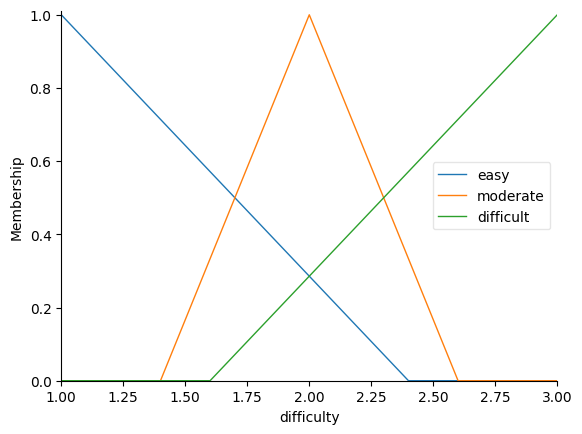

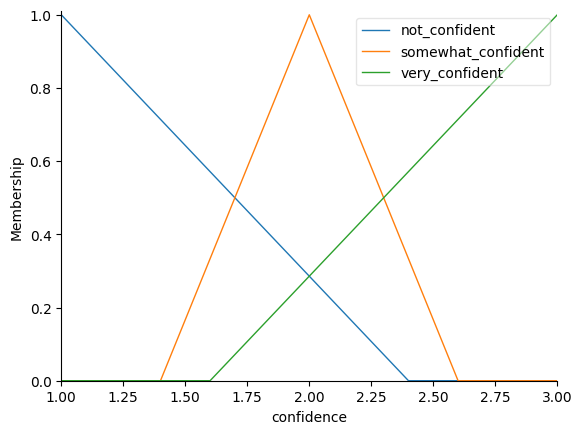

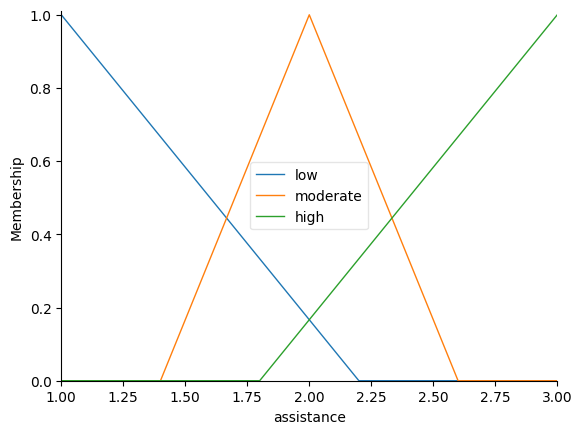

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Define the universe of discourse
universe = np.linspace(1, 3, 21)

# Define input and output variables
difficulty = ctrl.Antecedent(universe, 'difficulty')
confidence = ctrl.Antecedent(universe, 'confidence')
assistance = ctrl.Consequent(universe, 'assistance')



# Difficulty
difficulty['easy'] = fuzz.trimf(universe, [1, 1, 2.4])
difficulty['moderate'] = fuzz.trimf(universe, [1.4, 2, 2.6])
difficulty['difficult'] = fuzz.trimf(universe, [1.6, 3, 3])

# Confidence
confidence['not_confident'] = fuzz.trimf(universe, [1, 1, 2.4])
confidence['somewhat_confident'] = fuzz.trimf(universe, [1.4, 2, 2.6])
confidence['very_confident'] = fuzz.trimf(universe, [1.6, 3, 3])

# Assistance
assistance['low'] = fuzz.trimf(universe, [1, 1, 2.2])
assistance['moderate'] = fuzz.trimf(universe, [1.4, 2, 2.6])
assistance['high'] = fuzz.trimf(universe, [1.8, 3, 3])

difficulty.view()
plt.show()

confidence.view()
plt.show()

assistance.view()
plt.show()

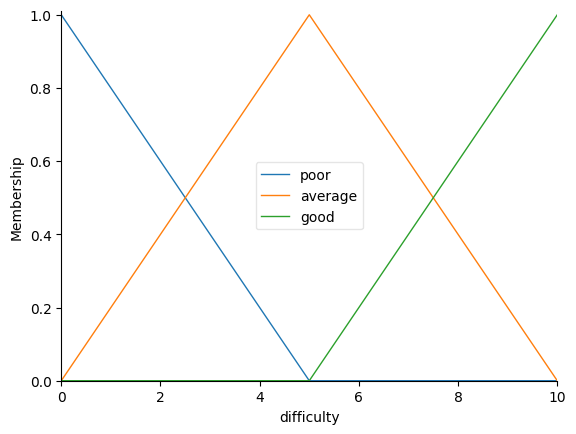

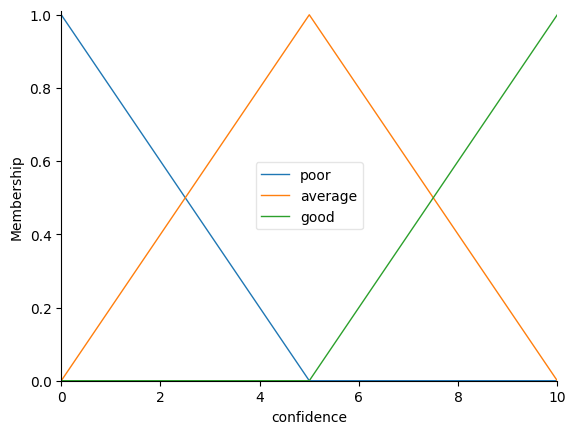

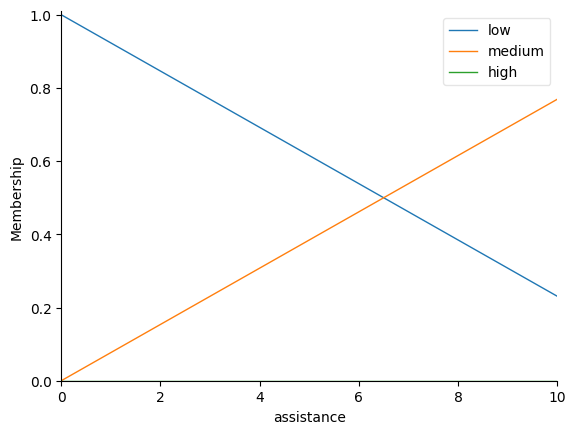

In [34]:
difficulty.view()
plt.show()

confidence.view()
plt.show()

assistance.view()
plt.show()

## Fuzzy Rules

1. **If the difficulty is easy AND the user is not confident, THEN the assistance will be moderate.**
2. **If the difficulty is easy AND the user is somewhat confident, THEN the assistance will be low.**
3. **If the difficulty is easy AND the user is very confident, THEN the assistance will be low.**
4. **If the difficulty is moderate AND the user is not confident, THEN the assistance will be high.**
5. **If the difficulty is moderate AND the user is somewhat confident, THEN the assistance will be moderate.**
6. **If the difficulty is moderate AND the user is very confident, THEN the assistance will be moderate.**
7. **If the difficulty is difficult AND the user is not confident, THEN the assistance will be high.**
8. **If the difficulty is difficult AND the user is somewhat confident, THEN the assistance will be high.**
9. **If the difficulty is difficult AND the user is very confident, THEN the assistance will be moderate.**


(<Figure size 640x480 with 1 Axes>, <Axes: >)

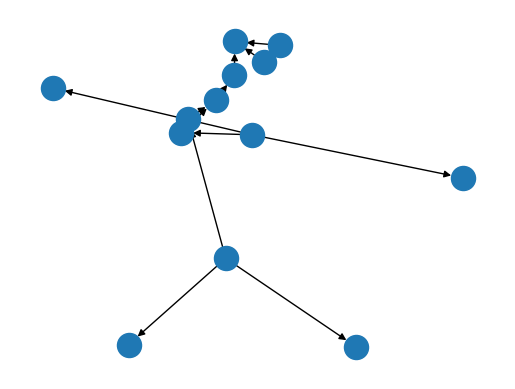

In [40]:
rule1 = ctrl.Rule(
    difficulty['easy'] & confidence['not_confident'],
    assistance['moderate']
)

rule2 = ctrl.Rule(
    difficulty['easy'] & confidence['somewhat_confident'],
    assistance['low']
)

rule3 = ctrl.Rule(
    difficulty['easy'] & confidence['very_confident'],
    assistance['low']
)

rule4 = ctrl.Rule(
    difficulty['moderate'] & confidence['not_confident'],
    assistance['high']
)

rule5 = ctrl.Rule(
    difficulty['moderate'] & confidence['somewhat_confident'],
    assistance['moderate']
)

rule6 = ctrl.Rule(
    difficulty['moderate'] & confidence['very_confident'],
    assistance['moderate']
)

rule7 = ctrl.Rule(
    difficulty['difficult'] & confidence['not_confident'],
    assistance['high']
)

rule8 = ctrl.Rule(
    difficulty['difficult'] & confidence['somewhat_confident'],
    assistance['high']
)

rule9 = ctrl.Rule(
    difficulty['difficult'] & confidence['very_confident'],
    assistance['moderate']
)

rule1.view()

## 4. Control System Creation and Simulation

In [45]:
assistance_simulation = ctrl.ControlSystem(rules)


2.5999999999999996


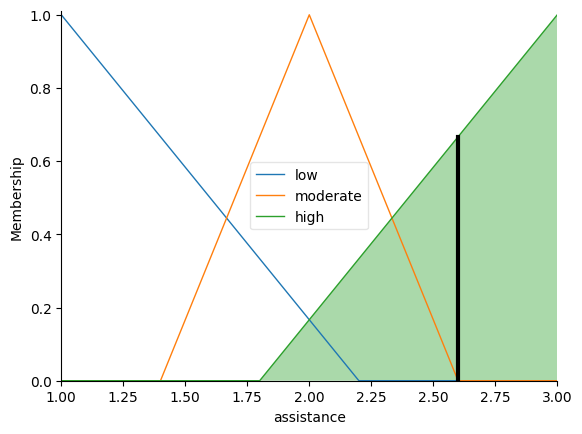

In [52]:
assistance_ctrl = ctrl.ControlSystem(rules)

assistance_simulation = ctrl.ControlSystemSimulation(
    assistance_ctrl
)

# Pass inputs to the ControlSystem
# Example: difficult situation and not confident
assistance_simulation.input['difficulty'] = 3
assistance_simulation.input['confidence'] = 1

# Crunch the numbers
assistance_simulation.compute()

# View the result and visualize the output
print(assistance_simulation.output['assistance'])
assistance.view(sim=assistance_simulation)